# Uber Eats Operational & Customer Intelligence System
## Exploratory Data Analysis (EDA)

**Purpose:** Explore the synthetic datasets, assess data quality, and understand customer, order, delivery, restaurant, and review patterns.

**Important:** These are synthetic educational data, not real Uber Eats operational records.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
print("Project directory:", PROJECT_ROOT)
print("Raw data directory exists:", DATA_DIR.exists())

Project directory: /home/nineleaps/uber-eats-capstone
Raw data directory exists: True


In [2]:
# Load available raw datasets
datasets = {}
for file in sorted(DATA_DIR.glob("*.csv")):
    name = file.stem
    datasets[name] = pd.read_csv(file)
    print(f"{name}: {datasets[name].shape[0]} rows, {datasets[name].shape[1]} columns")

if not datasets:
    raise FileNotFoundError(f"No CSV datasets found in {DATA_DIR}")

customers: 200 rows, 4 columns
deliveries: 1000 rows, 5 columns
drivers: 40 rows, 3 columns
orders: 1000 rows, 6 columns
payments: 1000 rows, 4 columns
restaurants: 30 rows, 5 columns
reviews: 500 rows, 4 columns


## 1. Dataset structure and data quality

Review column types, missing values, and duplicate rows for each source dataset.

In [3]:
for name, df in datasets.items():
    print("\\n" + "=" * 65)
    print(f"DATASET: {name}")
    print("=" * 65)
    display(df.head())
    print("\\nColumn types:")
    print(df.dtypes)
    print("\\nMissing values:")
    print(df.isna().sum())
    print("\\nDuplicate rows:", df.duplicated().sum())

\n=================================================================
DATASET: customers


,customer_id,customer_name,city,signup_date
0,1,Allison Hill,East Jill,2026-02-28
1,2,Angie Henderson,North Jefferyhaven,2026-01-05
2,3,Michelle Miles,Robinsonshire,2025-05-13
3,4,Olivia Moore,Petersonberg,2025-03-28
4,5,Ashley James,Melanieview,2026-06-04


\nColumn types:
customer_id      int64
customer_name      str
city               str
signup_date        str
dtype: object
\nMissing values:
customer_id      0
customer_name    0
city             0
signup_date      0
dtype: int64
\nDuplicate rows: 0
\n=================================================================
DATASET: deliveries


,delivery_id,order_id,driver_id,delivery_time_min,distance_km
0,1,1,32,49,5.3
1,2,2,32,17,2.3
2,3,3,15,53,4.1
3,4,4,34,45,1.0
4,5,5,40,27,12.3


\nColumn types:
delivery_id            int64
order_id               int64
driver_id              int64
delivery_time_min      int64
distance_km          float64
dtype: object
\nMissing values:
delivery_id          0
order_id             0
driver_id            0
delivery_time_min    0
distance_km          0
dtype: int64
\nDuplicate rows: 0
\n=================================================================
DATASET: drivers


...

\nColumn types:
payment_id        int64
order_id          int64
payment_method      str
payment_status      str
dtype: object
\nMissing values:
payment_id        0
order_id          0
payment_method    0
payment_status    0
dtype: int64
\nDuplicate rows: 0
\n=================================================================
DATASET: restaurants


,restaurant_id,restaurant_name,city,cuisine,rating
0,1,Conley PLC,Rodriguezport,Indian,3.1
1,2,Turner Inc,South Danielle,Chinese,3.5
2,3,"Bryant, Rodriguez and Stein",Lake Zacharybury,Italian,4.5
3,4,"Thomas, Patterson and Mendez",New Robert,American,3.2
4,5,"Barnett, Mills and Ward",South Morganton,Mexican,3.1


\nColumn types:
restaurant_id        int64
restaurant_name        str
city                   str
cuisine                str
rating             float64
dtype: object
\nMissing values:
restaurant_id      0
restaurant_name    0
city               0
cuisine            0
rating             0
dtype: int64
\nDuplicate rows: 0
\n=================================================================
DATASET: reviews


,review_id,order_id,review_text,review_rating
0,1,1,"Order was okay, nothing special",4
1,2,2,Food was cold and delivery was late,1
2,3,3,Food was cold and delivery was late,4
3,4,4,"Order was okay, nothing special",5
4,5,5,"Order was okay, nothing special",5


\nColumn types:
review_id        int64
order_id         int64
review_text        str
review_rating    int64
dtype: object
\nMissing values:
review_id        0
order_id         0
review_text      0
review_rating    0
dtype: int64
\nDuplicate rows: 0


## 2. Numeric summaries

Summary statistics help identify typical values, spread, and possible unusual values. These summaries alone do not prove that any value is erroneous.

In [4]:
for name, df in datasets.items():
    numeric = df.select_dtypes(include="number")
    if not numeric.empty:
        print(f"\\n{name} — numeric summary")
        display(numeric.describe().T.round(2))

\ncustomers — numeric summary


,count,mean,std,min,25%,50%,75%,max
customer_id,200.0,100.5,57.88,1.0,50.75,100.5,150.25,200.0


\ndeliveries — numeric summary


,count,mean,std,min,25%,50%,75%,max
delivery_id,1000.0,500.50,288.82,1.0,250.75,500.5,750.25,1000.0
order_id,1000.0,500.50,288.82,1.0,250.75,500.5,750.25,1000.0
driver_id,1000.0,20.88,11.93,1.0,10.00,21.0,32.00,40.0
delivery_time_min,1000.0,42.79,15.86,15.0,29.00,44.0,56.00,70.0
distance_km,1000.0,8.07,3.96,1.0,4.60,8.3,11.40,15.0


\ndrivers — numeric summary


...

,count,mean,std,min,25%,50%,75%,max
payment_id,1000.0,500.5,288.82,1.0,250.75,500.5,750.25,1000.0
order_id,1000.0,500.5,288.82,1.0,250.75,500.5,750.25,1000.0


\nrestaurants — numeric summary


,count,mean,std,min,25%,50%,75%,max
restaurant_id,30.0,15.50,8.80,1.0,8.25,15.5,22.75,30.0
rating,30.0,3.87,0.62,3.1,3.22,3.8,4.47,4.9


\nreviews — numeric summary


,count,mean,std,min,25%,50%,75%,max
review_id,500.0,250.50,144.48,1.0,125.75,250.5,375.25,500.0
order_id,500.0,250.50,144.48,1.0,125.75,250.5,375.25,500.0
review_rating,500.0,3.03,1.45,1.0,2.00,3.0,4.00,5.0


## 3. Order amounts and order status

,order_id,customer_id,restaurant_id,order_date,order_amount,order_status
0,1,36,8,2026-10-23T15:17:21.021484,77.05,Delayed
1,2,68,24,2026-10-23T15:16:14.787462,62.61,Delayed
2,3,103,12,2026-10-23T15:12:54.660837,29.74,Delivered
3,4,131,16,2026-10-23T15:14:46.284106,18.18,Delivered
4,5,29,5,2026-10-23T15:14:43.028045,66.47,Delayed


count    1000.000000
mean       55.881650
std        25.613515
min        10.060000
25%        35.045000
50%        56.025000
75%        77.900000
max        99.960000
Name: order_amount, dtype: float64


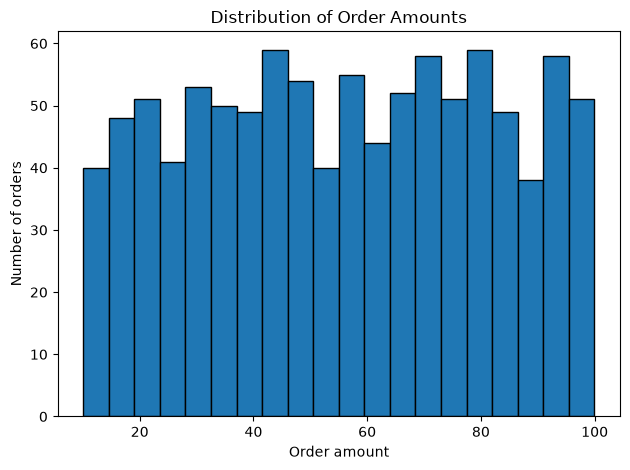

Order status counts:


,count
order_status,
Cancelled,345
Delivered,331
Delayed,324


In [5]:
orders = datasets.get("orders")
if orders is not None:
    display(orders.head())
    if "order_amount" in orders.columns:
        print(orders["order_amount"].describe())
        orders["order_amount"].dropna().plot(
            kind="hist", bins=20, edgecolor="black",
            title="Distribution of Order Amounts"
        )
        plt.xlabel("Order amount")
        plt.ylabel("Number of orders")
        plt.tight_layout()
        plt.show()
    if "order_status" in orders.columns:
        print("Order status counts:")
        display(orders["order_status"].value_counts(dropna=False).to_frame("count"))
else:
    print("orders.csv was not found.")

## 4. Delivery-time analysis

,delivery_id,order_id,driver_id,delivery_time_min,distance_km
0,1,1,32,49,5.3
1,2,2,32,17,2.3
2,3,3,15,53,4.1
3,4,4,34,45,1.0
4,5,5,40,27,12.3


count    1000.000000
mean       42.786000
std        15.855965
min        15.000000
25%        29.000000
50%        44.000000
75%        56.000000
max        70.000000
Name: delivery_time_min, dtype: float64


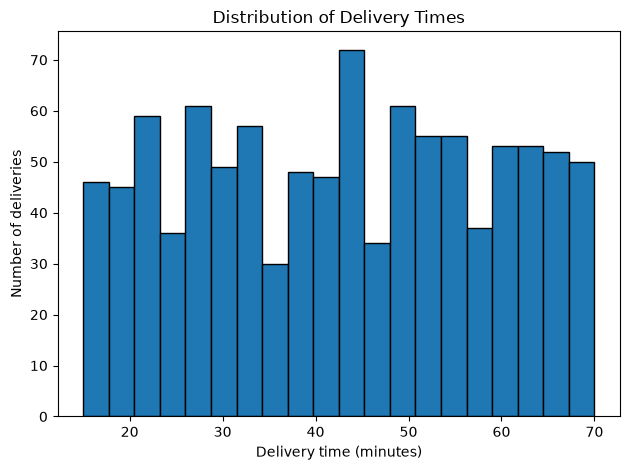

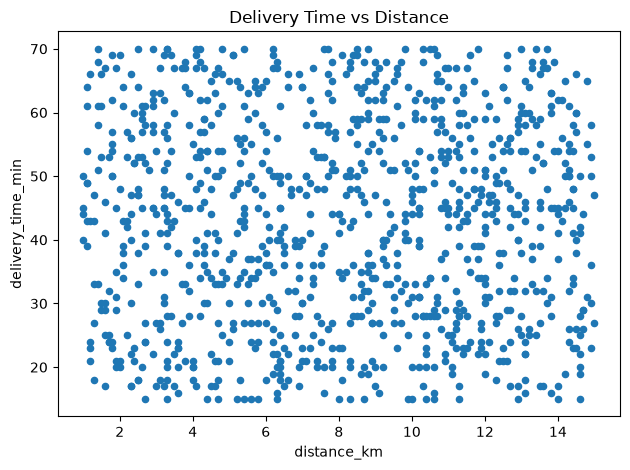

In [6]:
deliveries = datasets.get("deliveries")
if deliveries is not None:
    display(deliveries.head())
    if "delivery_time_min" in deliveries.columns:
        print(deliveries["delivery_time_min"].describe())
        deliveries["delivery_time_min"].dropna().plot(
            kind="hist", bins=20, edgecolor="black",
            title="Distribution of Delivery Times"
        )
        plt.xlabel("Delivery time (minutes)")
        plt.ylabel("Number of deliveries")
        plt.tight_layout()
        plt.show()
    if {"distance_km", "delivery_time_min"}.issubset(deliveries.columns):
        deliveries.plot(
            kind="scatter", x="distance_km", y="delivery_time_min",
            title="Delivery Time vs Distance"
        )
        plt.tight_layout()
        plt.show()
else:
    print("deliveries.csv was not found.")

## 5. Review ratings

,review_id,order_id,review_text,review_rating
0,1,1,"Order was okay, nothing special",4
1,2,2,Food was cold and delivery was late,1
2,3,3,Food was cold and delivery was late,4
3,4,4,"Order was okay, nothing special",5
4,5,5,"Order was okay, nothing special",5


Rating counts:


,count
review_rating,
1,105
2,96
3,86
4,106
5,107


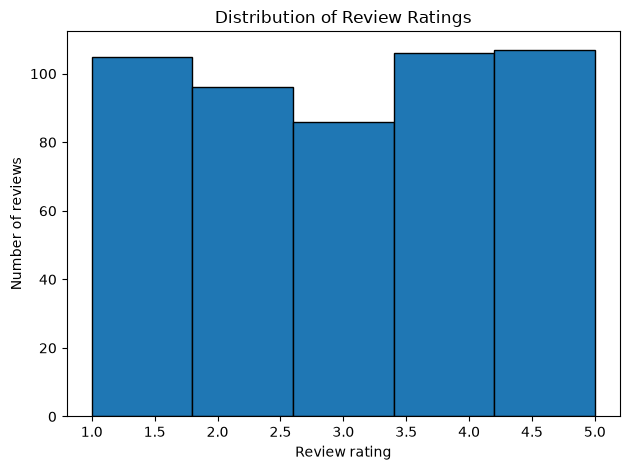

Missing review text: 0
Unique review texts: 6


In [7]:
reviews = datasets.get("reviews")
if reviews is not None:
    display(reviews.head())
    if "review_rating" in reviews.columns:
        print("Rating counts:")
        display(reviews["review_rating"].value_counts(dropna=False).sort_index().to_frame("count"))
        reviews["review_rating"].dropna().plot(
            kind="hist", bins=5, edgecolor="black",
            title="Distribution of Review Ratings"
        )
        plt.xlabel("Review rating")
        plt.ylabel("Number of reviews")
        plt.tight_layout()
        plt.show()
    if "review_text" in reviews.columns:
        print("Missing review text:", reviews["review_text"].isna().sum())
        print("Unique review texts:", reviews["review_text"].nunique(dropna=True))
else:
    print("reviews.csv was not found.")

## 6. Correlation analysis

Correlations describe linear associations between numeric columns; they do not establish causation.

\norders — numeric correlations


,order_id,customer_id,restaurant_id,order_amount
order_id,1.000,0.016,0.004,0.009
customer_id,0.016,1.000,0.035,-0.039
restaurant_id,0.004,0.035,1.000,-0.020
order_amount,0.009,-0.039,-0.020,1.000


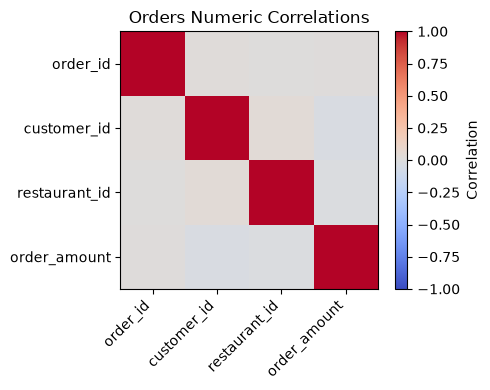

\ndeliveries — numeric correlations


,delivery_id,order_id,driver_id,delivery_time_min,distance_km
delivery_id,1.000,1.000,-0.011,-0.018,-0.001
order_id,1.000,1.000,-0.011,-0.018,-0.001
driver_id,-0.011,-0.011,1.000,0.012,-0.008
delivery_time_min,-0.018,-0.018,0.012,1.000,0.008
distance_km,-0.001,-0.001,-0.008,0.008,1.000


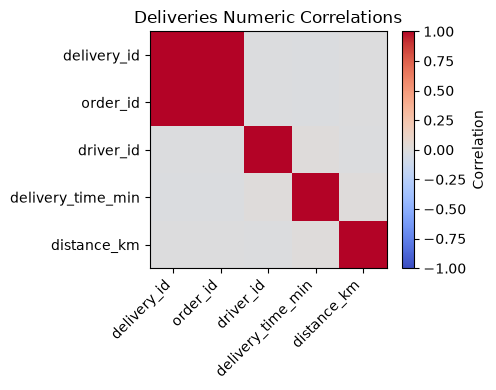

\nrestaurants — numeric correlations


,restaurant_id,rating
restaurant_id,1.000,0.193
rating,0.193,1.000


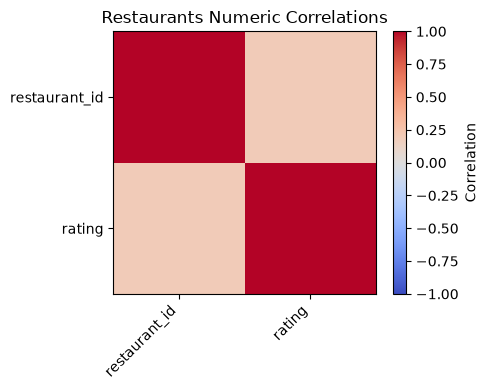

\npayments — numeric correlations


,payment_id,order_id
payment_id,1.0,1.0
order_id,1.0,1.0


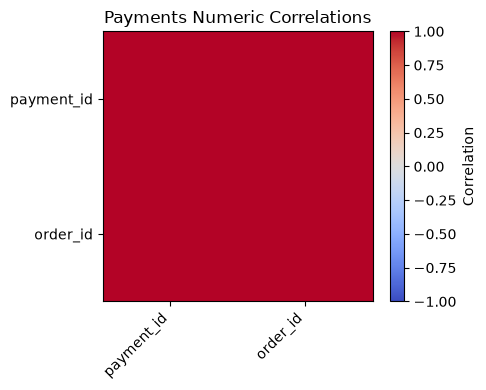

In [8]:
for name in ["orders", "deliveries", "restaurants", "payments"]:
    df = datasets.get(name)
    if df is None:
        continue
    numeric = df.select_dtypes(include="number")
    if numeric.shape[1] >= 2:
        print(f"\\n{name} — numeric correlations")
        display(numeric.corr().round(3))
        corr = numeric.corr()
        fig, ax = plt.subplots(figsize=(max(5, len(corr.columns)), max(4, len(corr.columns) * 0.7)))
        image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
        ax.set_xticks(range(len(corr.columns)))
        ax.set_yticks(range(len(corr.columns)))
        ax.set_xticklabels(corr.columns, rotation=45, ha="right")
        ax.set_yticklabels(corr.columns)
        fig.colorbar(image, ax=ax, label="Correlation")
        ax.set_title(f"{name.title()} Numeric Correlations")
        fig.tight_layout()
        plt.show()

## 7. Key findings and limitations

Use the executed outputs above to record findings. Initial known project limitations include:

- The data is synthetic and should not be treated as representative of real platform operations.
- Order timestamps cover only a very short time window, so meaningful hourly or seasonal forecasting is not possible.
- Review texts are repetitive and can have conflicting rating labels, limiting sentiment-model reliability.
- Traffic, weather, preparation time, and pickup waiting time are unavailable for delivery-time modeling.
- Correlation and model feature importance do not prove causal relationships.

### Conclusion

This notebook provides an exploratory overview of the available raw data. It complements the project’s existing feature-engineering, clustering, sentiment, regression, and forecasting scripts. Add concise, evidence-based findings after running all cells.